# 1. Data and geological constraints

The cohort, the screening policy, the records left out of the main comparison, and the geological information that restricts grouping. All tables are read from `results/`; `evcca-reproduce` recomputes them.

In [1]:
import pandas as pd
from IPython.display import display

from evcca import Policy
from evcca.policy import NU_TABLE_2012, NU_TABLE_AMENDMENT_1
from evcca.study import ficlay
from evcca.study.barriers import primary_barriers
from evcca.study.cohort import article_policy, load_specimens
from evcca.study.notebook import record, show_figure, table
from evcca.study.paths import DATA

## 1.1 Cohort

A context is one site and one material (for the export, also one confining pressure). The active cohort has 19 contexts and 247 specimens. The export projects P11, P12 and P16 are kept in `all_specimens.csv` but left out of the main comparison (Section 1.3).

In [2]:
specimens = load_specimens()
specimens.assign(hole=specimens.site_id + "/" + specimens.borehole_id).groupby("dataset").agg(
    sites=("site_id", "nunique"),
    contexts=("context_id", "nunique"),
    boreholes=("hole", "nunique"),
    specimens=("sample_id", "size"),
)

,sites,contexts,boreholes,specimens
dataset,,,,
EXPORT,3,3,30,36
FI-CLAY,5,5,15,95
PRIMARY,4,11,48,116


In [3]:
registry = pd.read_csv(DATA / "processed/cohort_registry.csv")
registry[~registry.active]

,dataset,site_id,context_id,specimens,boreholes,active,excluded_because
7,EXPORT,P11,P11 | LOAM | m | sigma3=65.0,14,14,False,export strength fields not comparable
8,EXPORT,P12,P12 | LOAM | m | sigma3=50.0,19,10,False,export strength fields not comparable
10,EXPORT,P16,P16 | LOAM | g | sigma3=100.0,46,6,False,export strength fields not comparable
11,EXPORT,P16,P16 | SANDY_LOAM | f | sigma3=100.0,12,3,False,export strength fields not comparable


The FI-CLAY specimens are selected from the unchanged workbook by `evcca.study.ficlay.select`: ordinary incrementally loaded tests with measured compression index, clay as the principal soil type, a consistent sample depth interval and all four properties positive (see its docstring and `data/README.md`). The selection reproduces the released rows:

In [4]:
selected = ficlay.select()
released = load_specimens(active=False).query("dataset == 'FI-CLAY'").sort_values("sample_id")
print("same records:", selected.sample_id.tolist() == released.sample_id.tolist())
selected.groupby("site_id").size().rename("specimens")

same records: True


site_id
Haapa-Kimola          24
Haarajoki             21
Söderkulla-Nikkilä    18
Tolsa, Kirkkonummi    24
Östersundom            8
Name: specimens, dtype: int64

The five sites are not chosen by hand. Every context needs at least eight usable records from at least two boreholes; of the 33 sites in the workbook, exactly five meet that rule.

In [5]:
ficlay.site_counts().head(8)

,records,boreholes,eligible
site,,,
"Tolsa, Kirkkonummi",24,3,True
Haapa-Kimola,24,2,True
Haarajoki,21,2,True
Söderkulla-Nikkilä,18,4,True
Kujala test embankment (5.5 m),9,1,False
Östersundom,8,4,True
POKO,7,3,False
"Suurpelto, Espoo",6,3,False


## 1.2 Screening policy

Physical properties are limited to CV ≤ 0.15 and mechanical ones to CV ≤ 0.30. The extremum statistic uses the sample standard deviation and the critical values of GOST 20522-2012 as amended in 2024. A group needs at least six specimens, and a context may refer at most max(1, ⌊0.1 n⌋) specimens for review.

In [6]:
pd.DataFrame(
    {
        "properties": [article_policy("PRIMARY").properties, article_policy("FI-CLAY").properties],
        "CV limits": [article_policy("PRIMARY").limits, article_policy("FI-CLAY").limits],
    },
    index=["project records", "FI-CLAY"],
)

,properties,CV limits
project records,"(rho, e0, cohesion, modulus)","(0.15, 0.15, 0.3, 0.3)"
FI-CLAY,"(alpha, rho, water_pct, su)","(0.3, 0.15, 0.15, 0.3)"


In [7]:
policy = Policy()
pd.Series(
    {
        "minimum group size": policy.min_size,
        "review budget, n = 17": policy.budget(17),
        "review budget, n = 24": policy.budget(24),
        "critical value table": policy.nu_table_version,
        "sample standard deviation": policy.nu_sample_sd,
    }
)

minimum group size                          6
review budget, n = 17                       1
review budget, n = 24                       2
critical value table         amendment_1_2024
sample standard deviation                True
dtype: object

The amendment lowers every critical value of the 2012 table. The amended values follow the two-sided 5 % Grubbs criterion closely (the largest difference is 0.012), but the computation uses the published values.

In [8]:
critical = pd.DataFrame({"2012": NU_TABLE_2012, "2024": NU_TABLE_AMENDMENT_1}).loc[6:25]
critical.T

,6,7,8,9,10,11,12,13,14,...,17,18,19,20,21,22,23,24,25
2012,2.07,2.18,2.27,2.35,2.41,2.47,2.52,2.56,2.60,...,2.70,2.73,2.75,2.78,2.80,2.82,2.84,2.86,2.88
2024,1.89,2.02,2.13,2.22,2.29,2.36,2.41,2.46,2.51,...,2.62,2.65,2.68,2.71,2.73,2.76,2.78,2.80,2.82


In [9]:
table("grubbs_comparison").set_index("n").loc[[6, 10, 16, 24, 50]].round(3)

,reference,two_sided_grubbs_5pct,difference
n,,,
6,1.89,1.887,0.003
10,2.29,2.290,0.000
16,2.59,2.586,0.004
24,2.80,2.802,-0.002
50,3.14,3.128,0.012


## 1.3 Export projects left out

In the triaxial export, P11, P12 and P16 store cohesion in a way that is not comparable with the other projects: many records have φ = 0 and c [MPa] = q_f [kPa] / 2000, which suggests an undrained-strength convention. The comparison therefore excludes these projects as a whole.

In [10]:
signature = table("strength_signature")
signature.groupby("site_id")[["n", "zero_angle", "signature"]].sum()

,n,zero_angle,signature
site_id,,,
P07,12,0,0
P09,12,0,0
P11,14,9,9
P12,19,19,19
P15,12,0,0
P16,58,22,22


Removing only the signature rows instead of whole projects leaves the following contexts (those with at least eight records and two boreholes).

In [11]:
table("row_signature_sensitivity")[["context_id", "method", "n", "A", "K", "strict_feasible", "strict_accepted_n"]]

,context_id,method,n,A,K,strict_feasible,strict_accepted_n
0,P16 | LOAM | g | sigma3=100.0,ordered,24,0,3,True,24
1,P16 | LOAM | g | sigma3=100.0,evcca,24,0,2,True,24
2,P16 | SANDY_LOAM | f | sigma3=100.0,ordered,12,0,2,True,12
3,P16 | SANDY_LOAM | f | sigma3=100.0,evcca,12,0,2,True,12


## 1.4 Source units

The source interpretation (`initial_ige`) of the primary statements, screened with the same gates. Most failing units are smaller than the minimum of six specimens, so the screen alone does not show that they are geologically wrong.

In [12]:
units = table("source_unit_support")
pd.Series(
    {
        "source units": len(units),
        "admissible": int(units.compliant.sum()),
        "not admissible, fewer than six specimens": int((~units.compliant & units.below_minimum).sum()),
        "not admissible, six or more": int((~units.compliant & ~units.below_minimum).sum()),
    }
)

source units                                29
admissible                                   7
not admissible, fewer than six specimens    21
not admissible, six or more                  1
dtype: int64

The CV of the void ratio is typically about five times that of density.

In [13]:
ratio = table("void_ratio_density")
ratio.ratio.describe()[["count", "min", "50%", "max"]].round(2)

count    25.00
min       2.37
50%       4.88
max      11.14
Name: ratio, dtype: float64

Over every interval candidate of the primary contexts (at least six specimens, no barrier conflict), the density CV never exceeds 0.15, while the void-ratio CV often does. Density restricts groups only through the extremum gate.

In [14]:
table("robustness/gate_failures").groupby("property")[["candidates", "cv_fail", "extremum_fail"]].sum()

,candidates,cv_fail,extremum_fail
property,,,
cohesion,28774,372,1090
e0,28774,1655,2165
modulus,28774,320,566
rho,28774,0,812


## 1.5 Haarajoki dry crust

The FI-CLAY database has nine records in the upper 2 m at Haarajoki: seven ordinary incrementally loaded tests (ILOT) and two CRS tests with estimated compression indices, which the study does not use. Five ILOT records are complete; two lack only the fall-cone strength. One more complete record would reach the minimum of six. The crust is a `fixed_geological_unit`, so it cannot share a group with the clay below.

In [15]:
crust = record("haarajoki_crust")
missing = crust.pop("missing_property_counts")
display(pd.Series(crust))
pd.Series(missing, name="records without the value")

source_database_crust_records         9
ordinary_ilot_records                 7
complete_positive_property_records    5
incomplete_property_records           4
active_eligible_crust_records         5
dtype: int64

Void ratio                                   0
Compression index                            0
Unit weight (kN/m3)                          0
Water content (%)                            0
Undrained shear stregth (fall cone) (kPa)    4
Name: records without the value, dtype: int64

## 1.6 Logged barriers and the P13 loam

Two specimens of one material in one borehole may not share a group when the log shows a different material between them. The lists in `barrier_with_ids` follow from `primary_logs.csv`:

In [16]:
logs = pd.read_csv(DATA / "processed/primary_logs.csv")
primary_barriers(logs).tolist() == logs.barrier_with_ids.fillna("").tolist()

True

In borehole B013 of project P13, clay lies between the upper and the lower loam.

In [17]:
b013 = logs[logs.site_id.eq("P13") & logs.borehole_id.eq("B013")].sort_values("depth_m")
b013[b013.depth_m.between(40, 85)][["depth_m", "soil_family", "genesis", "initial_ige", "has_four_properties"]]

,depth_m,soil_family,genesis,initial_ige,has_four_properties
899,41.0,LOAM,C,U008,True
900,41.8,LOAM,NaN,U008,False
901,46.8,CLAY,NaN,U009,False
902,54.8,CLAY,C,U011,True
903,59.0,CLAY,C,U011,True
904,69.3,LOAM,NaN,U013,False
905,73.0,LOAM,NaN,U013,False
906,78.0,LOAM,C,U014,True


Both modes keep all 17 loam specimens in two groups. The compact groups mix upper and lower observations; repair keeps the source separation of the upper six and the lower eleven. No depth rule is added: the bands below only describe the result.

In [18]:
table("repair_depth_modes")

,mode,retained,A,K,D,cross_band_pairs,all_groups_compliant
0,compact,17,0,2,59,33,True
1,repair,17,0,2,39,0,True


In [19]:
table("repair_depth_groups")

,mode,group,n,upper_n,lower_n,depth_min,depth_max,source_units,compliant
0,compact,0,6,3,3,41.0,74.3,U008;U010;U013,True
1,compact,1,11,3,8,42.0,84.5,U008;U010;U013;U014,True
2,repair,0,11,0,11,67.0,84.5,U013;U014,True
3,repair,1,6,6,0,41.0,53.0,U008;U010,True


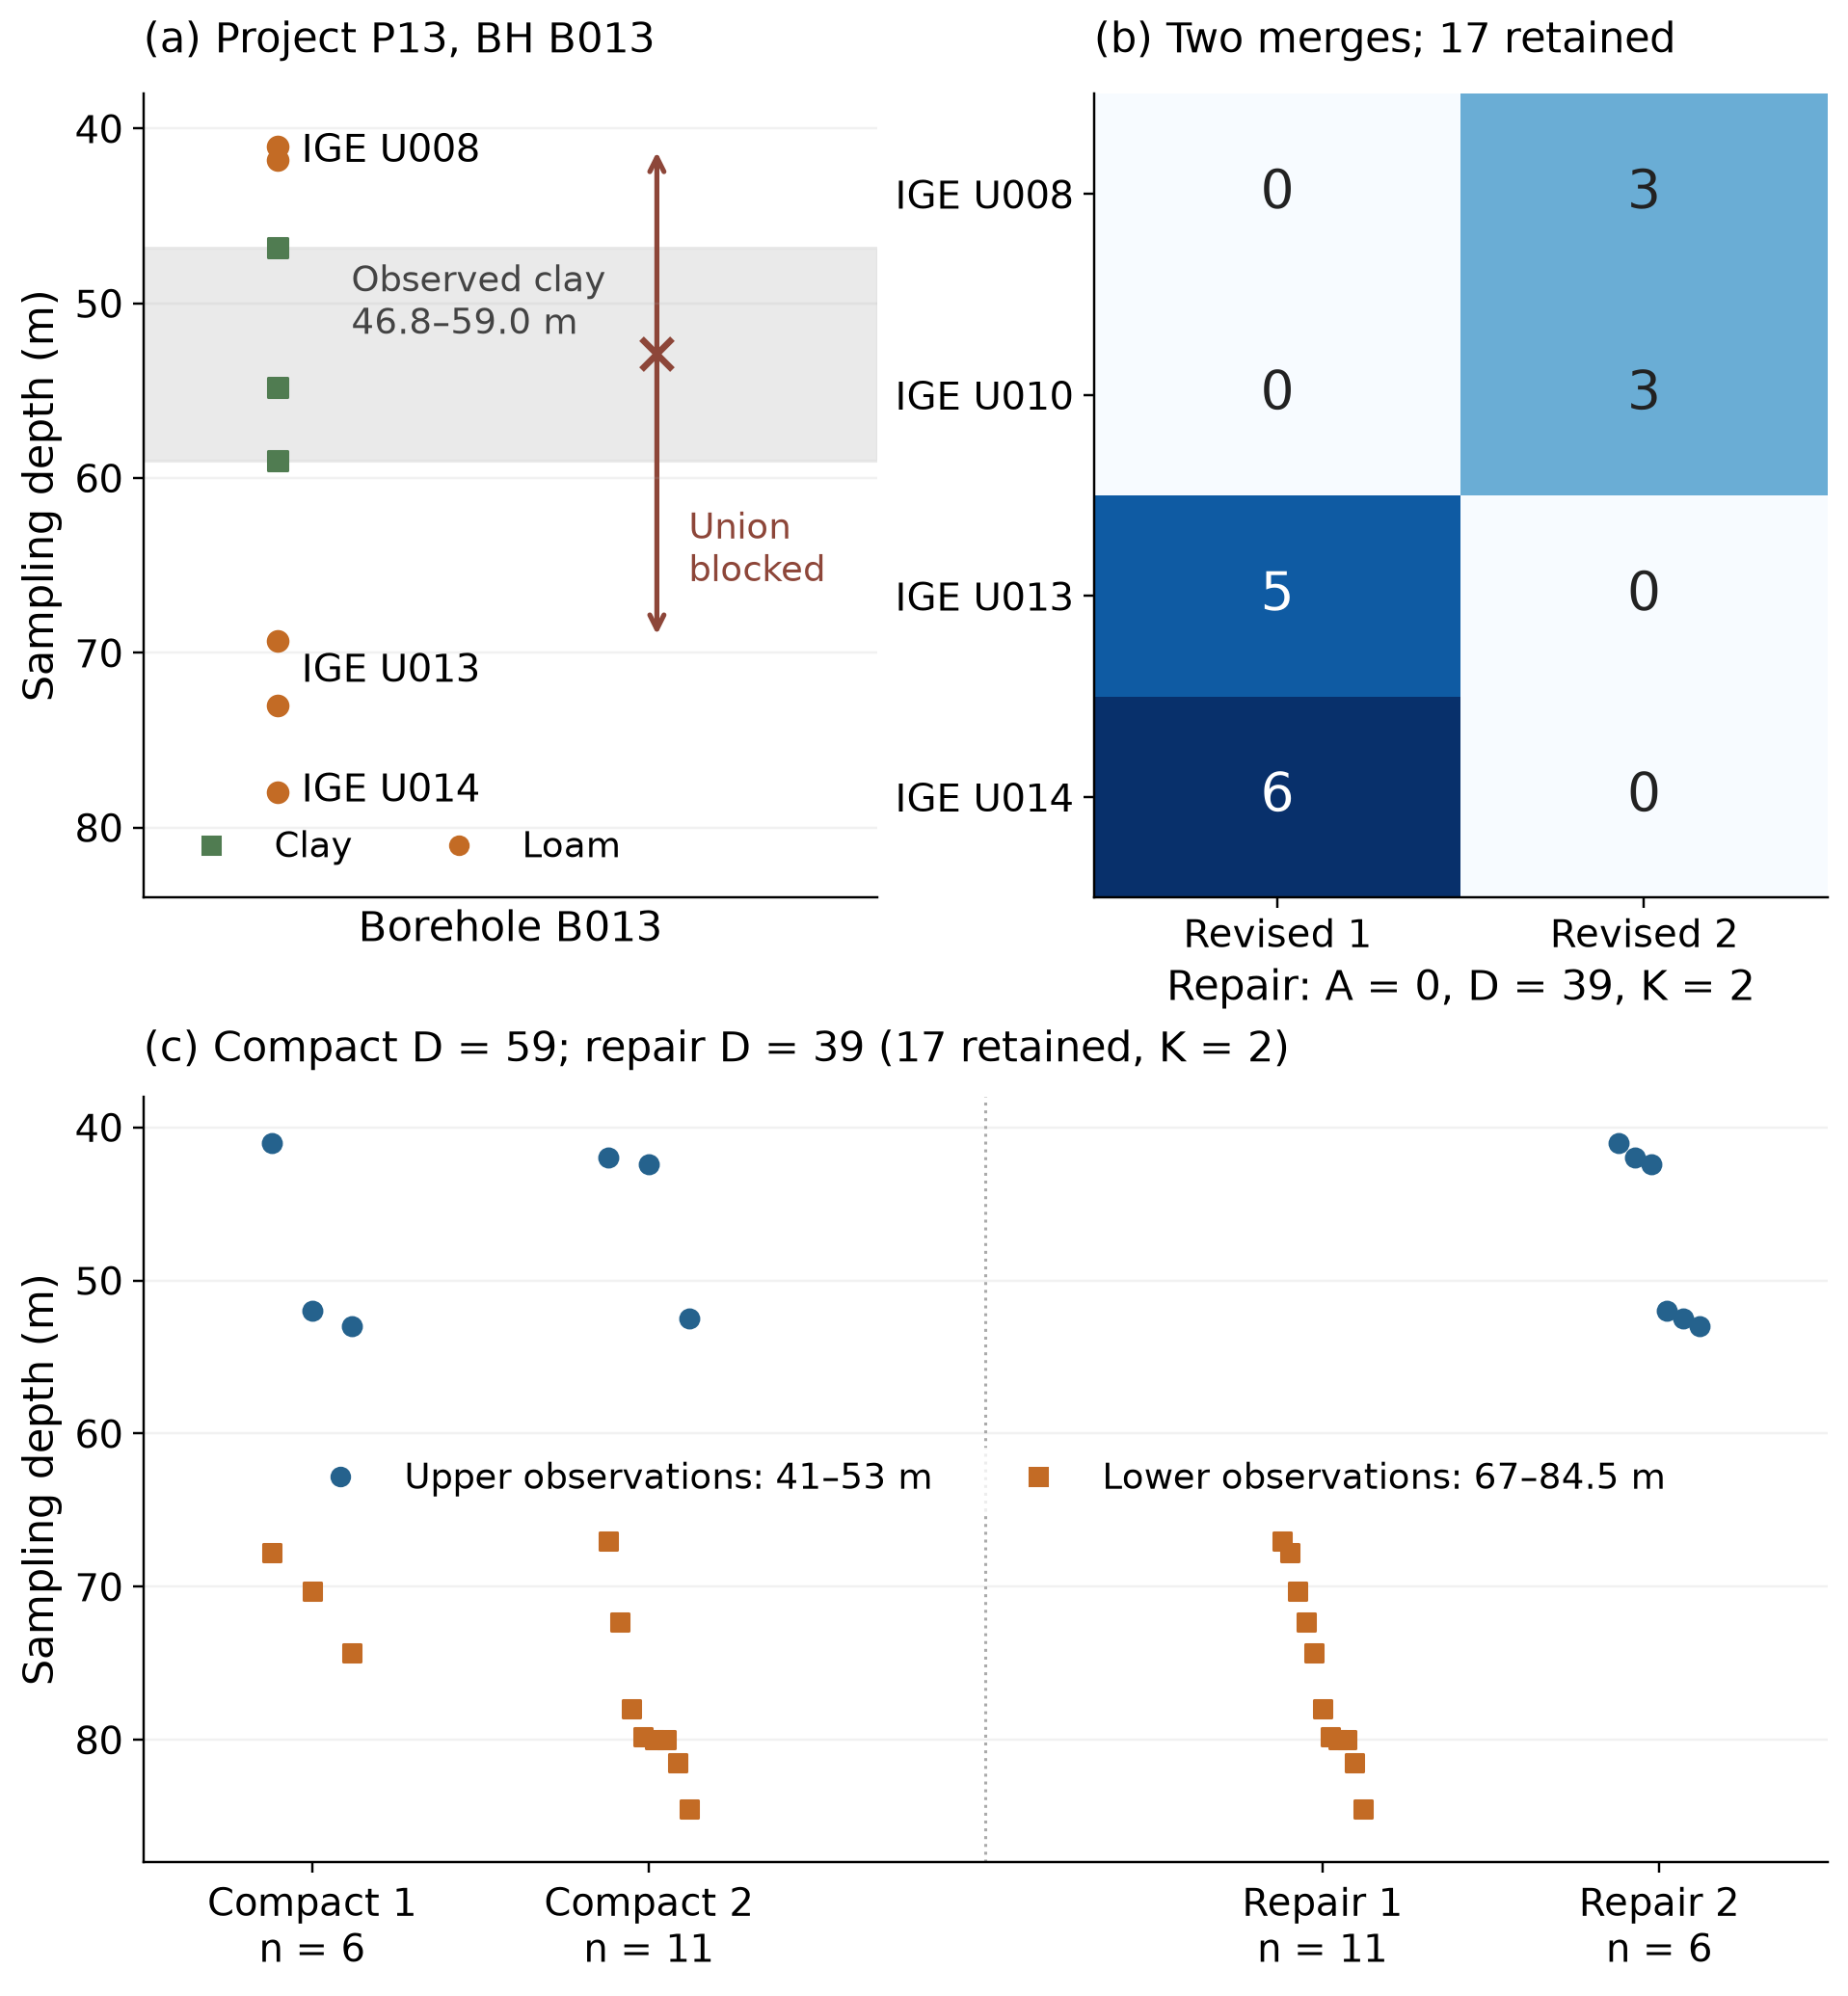

In [20]:
show_figure("fig2_revision_plan")